# Medicaid prescription spending: from dollars to review priorities

**Mohammed Mia | Healthcare Data Analytics | Python + SQL | 2024**

I built this analysis to understand where Medicaid prescription spending concentrates and which recorded product alternatives deserve closer price review. An expensive unit price and a large budget contribution are different things; a promising price difference also needs clinical and economic verification before it becomes actionable.

I follow five questions through the notebook:

1. **Q1:** Which product NDCs account for the most spending?
2. **Q2:** Which pharmacologic categories are prominent?
3. **Q3:** Where do matched prices suggest a useful starting point for a savings review?
4. **Q4:** Which products have potentially comparable recorded alternatives, and what remains unverified?
5. **Q5:** How do geography, reporting period, and product category affect the spending picture?

I first prepare the data, then connect each calculation to its finding and practical interpretation. The included extract covers **11 states and Washington, DC**, with **$27.54B in reported reimbursement before rebates**. Its findings do not represent a national spending estimate.


In [1]:
from pathlib import Path
import sys
import json
import sqlite3
import pandas as pd

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src/medicaid_analytics").exists())
sys.path.insert(0, str(ROOT / "src"))
from medicaid_analytics.pipeline import run
from medicaid_analytics.prepare import prepare_utilization, prepare_directory, attach_metadata
from medicaid_analytics.compare import reimbursement_gaps
from medicaid_analytics.verify import verify

if not (ROOT / "data/processed/analytics.sqlite").exists():
    run(ROOT)
summary = json.loads((ROOT / "reports/analysis_summary.json").read_text())
connection = sqlite3.connect(ROOT / "data/processed/analytics.sqlite")
print(summary["scope"])


2024 Medicaid utilization extract: 11 states and Washington, DC


## Preparing the data: what one record means

I start with two sources. A utilization observation represents one utilization type, jurisdiction, package NDC, year, and quarter. The product directory provides the descriptions needed to interpret and match products. Managed-care and fee-for-service rows remain separate observations.

I load NDCs as text to preserve leading zeros. I do not combine differently formatted codes until their labeler and product segments have been standardized.


In [2]:
columns = ["source_row", "Utilization Type", "State", "NDC", "Year", "Quarter",
           "Suppression Used", "Product Name", "Units Reimbursed",
           "Number of Prescriptions", "Medicaid Amount Reimbursed"]
records = pd.read_csv(ROOT / "data/raw/utilization.csv.gz", usecols=columns, dtype={"NDC": "string"})
product_records = pd.read_csv(ROOT / "data/raw/product_directory.csv.gz", dtype="string")
print(f"Utilization records: {len(records):,}")
print(f"Product listings: {len(product_records):,}")
print(records[["State", "NDC", "Quarter", "Suppression Used"]].head().to_string(index=False))


Utilization records: 1,048,575
Product listings: 113,878
State         NDC  Quarter  Suppression Used
   HI 00002015204        4                 1
   AK 00002021301        1                 1
   AL 00002021301        4                 0
   AL 00002021301        3                 0
   AL 00002021301        2                 0


### I keep missing amounts separate from zero

My first decision is which records can support dollar totals and which can support a unit price. I check reporting fields, NDC format, suppression, duplicate keys, and numeric values. Suppressed amounts remain missing. A unit-price calculation additionally requires positive units.

The shared preparation functions apply these rules consistently in the notebook and the pipeline; the [methodology](../docs/METHODOLOGY.md) explains them in detail.


In [3]:
utilization, record_stats = prepare_utilization(records)
print(f"Records with reported reimbursement: {record_stats['spend_eligible_records']:,}")
print(f"Records with suppressed amounts: {record_stats['suppressed_records']:,}")
print(f"Reported reimbursement: ${record_stats['observed_pre_rebate_reimbursement']:,.2f}")
print("Jurisdictions:", ", ".join(record_stats["observed_states"]))


Records with reported reimbursement: 504,630
Records with suppressed amounts: 543,945
Reported reimbursement: $27,539,974,390.90
Jurisdictions: AK, AL, AR, AZ, CA, CO, CT, DC, DE, FL, GA, HI


I retain **504,630 records with reported reimbursement** for spending analysis. Another **543,945 records have suppressed amounts**. Their counts remain useful for coverage reporting, but I cannot infer the dollars hidden by suppression.

### I attach descriptions without changing the spending total

I standardize the directory's segmented codes to the product portion of the package NDC. I collapse identical analytical descriptions, leave conflicting product keys unmatched, and require a many-to-one left join. This prevents duplicate directory rows from multiplying dollars and preserves reported spending even when a description cannot be attached.


In [4]:
directory, conflicts, directory_stats = prepare_directory(product_records)
joined, join_stats = attach_metadata(utilization, directory)
print(f"Conflicting product keys left unmatched: {directory_stats['conflicting_directory_keys']:,}")
print(f"Product metadata coverage by dollars: {join_stats['matched_spending_share']:.2%}")
print(f"Unmatched reimbursement retained in totals: ${join_stats['unmatched_reimbursement']:,.2f}")
print(f"Utilization rows before / after join: {len(utilization):,} / {len(joined):,}")


Conflicting product keys left unmatched: 424
Product metadata coverage by dollars: 99.42%
Unmatched reimbursement retained in totals: $160,852,518.29
Utilization rows before / after join: 1,048,575 / 1,048,575


Unambiguous descriptions cover **99.42% of reported dollars**. The remaining **$160.85M** stays in the spending denominator. This matters because a product's missing description should not make its reimbursement disappear from the budget picture.

## Q1. Which products account for the most spending?

I begin with total reimbursement, rather than unit price, to identify budget exposure. SQL aggregates eligible dollars by product key, assigns ranks with `ROW_NUMBER`, and calculates individual and cumulative shares with window functions.

A product NDC combines package sizes. Different strengths under the same brand can remain separate product keys.


In [5]:
products = pd.read_sql_query((ROOT / "sql/product_spending.sql").read_text(), connection)
top_products = products.head(10)[["product_key", "product_name", "reimbursement", "spend_share"]].copy()
top_products["reimbursement"] = top_products["reimbursement"].map(lambda x: f"${x:,.2f}")
top_products["spend_share"] = top_products["spend_share"].map(lambda x: f"{x:.2%}")
print(top_products.to_string(index=False))


product_key    product_name   reimbursement spend_share
  619582501        Biktarvy $907,888,446.52       3.30%
  000740554          Humira $633,429,714.83       2.30%
  001694181         Ozempic $527,796,714.03       1.92%
  001694130         Ozempic $404,945,247.57       1.47%
  504580564 INVEGA SUSTENNA $397,690,422.18       1.44%
  005970153       Jardiance $378,817,703.56       1.38%
  000245915        Dupixent $346,782,739.48       1.26%
  001694772         Ozempic $321,640,777.32       1.17%
  578940061         STELARA $305,253,951.05       1.11%
  005970152       Jardiance $290,855,662.37       1.06%


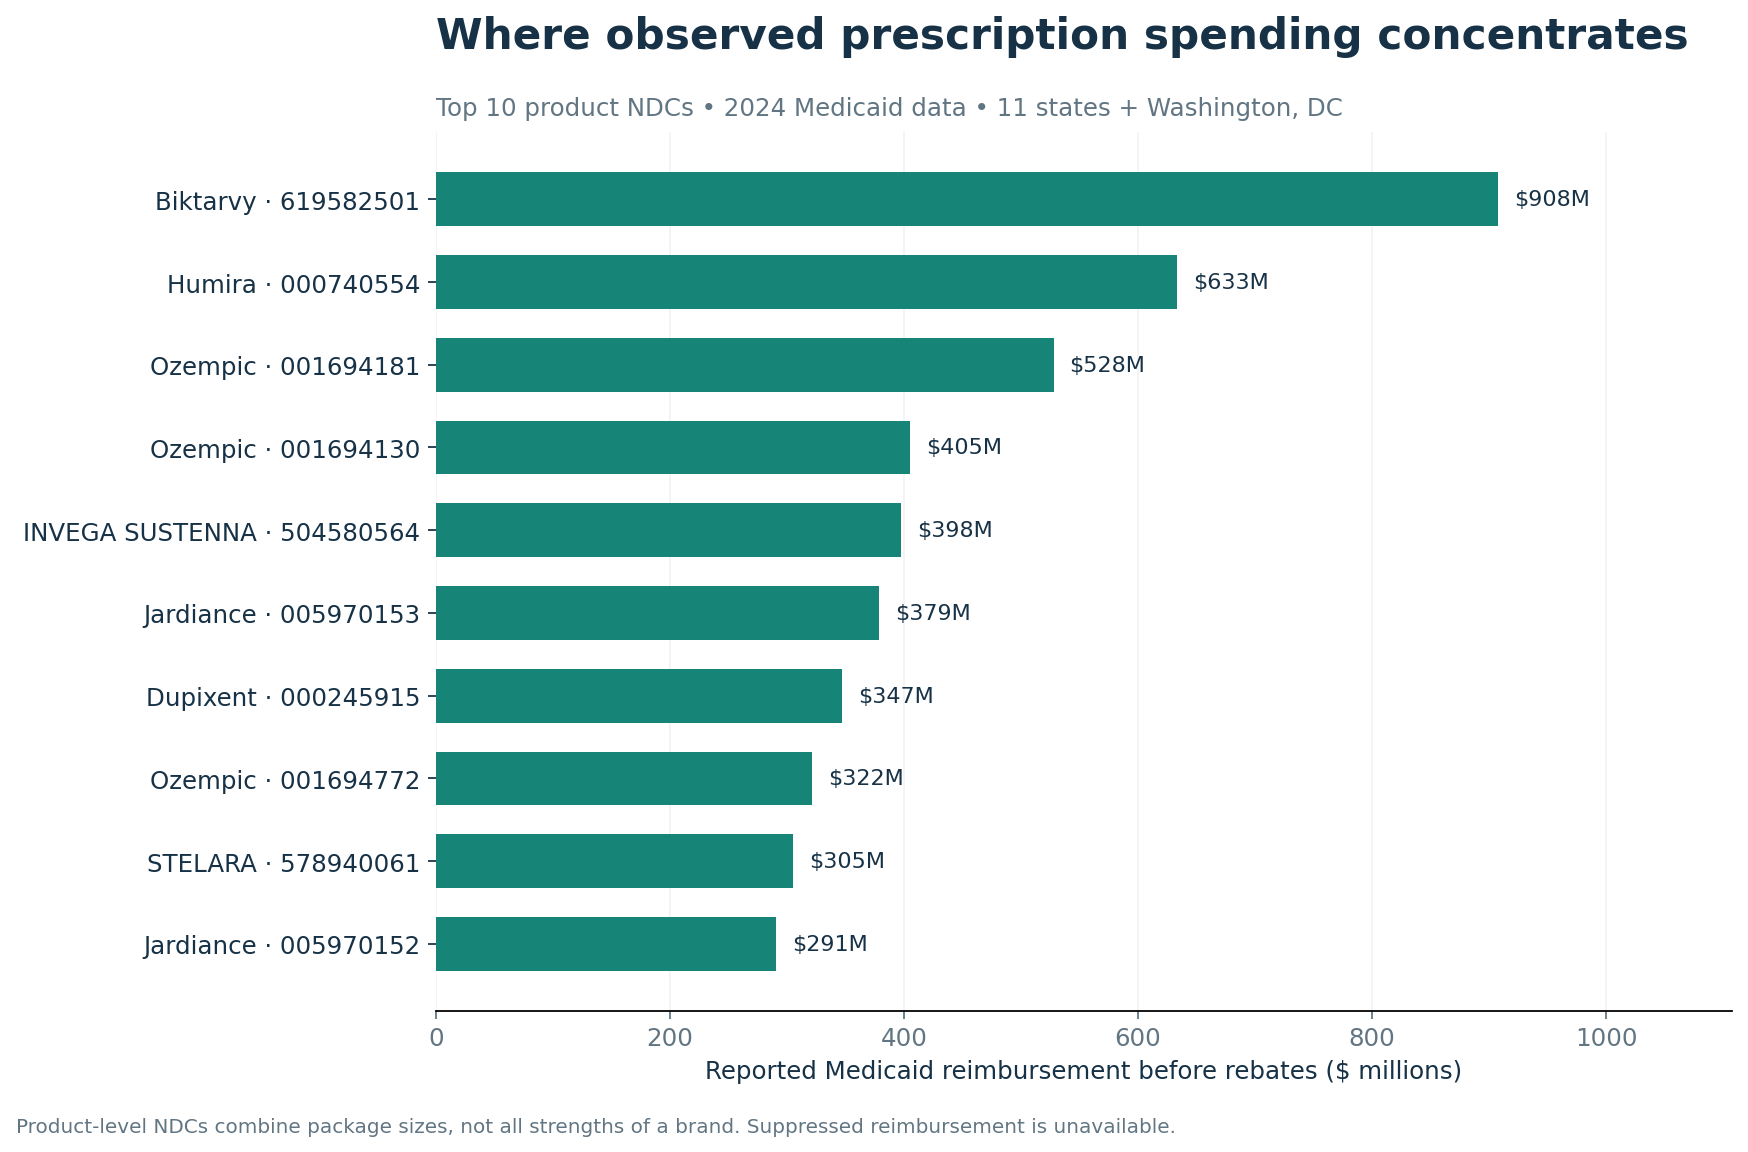

Biktarvy product NDC **619582501** accounts for **$907.89M**, the highest product-level amount. I next ask how quickly the highest-spending product set accumulates a substantial share of the total.


In [6]:
for count in [10, 50, 100]:
    share = products.head(count)["spend_share"].sum()
    print(f"Top {count} product NDCs: {share:.1%} of reported reimbursement")


Top 10 product NDCs: 16.4% of reported reimbursement
Top 50 product NDCs: 37.1% of reported reimbursement
Top 100 product NDCs: 49.5% of reported reimbursement


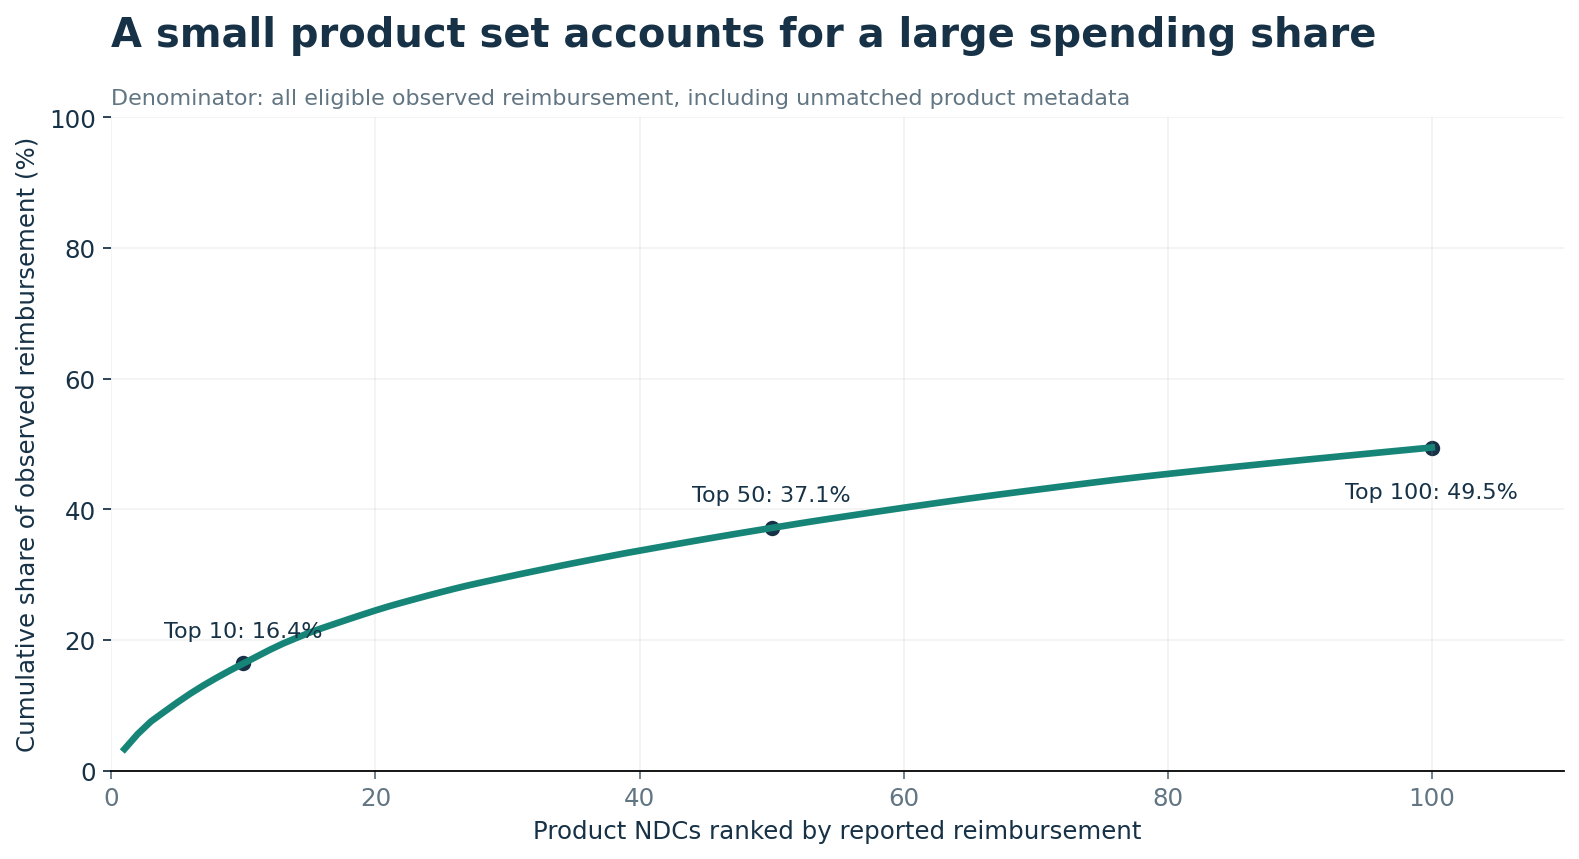

**What I learned:** the top 50 product NDCs account for **37.1%** of reimbursement. That gives me a focused starting point for detailed review. It does not establish that the spending is wasteful; it establishes where a closer look could cover a substantial dollar amount.

## Q2. Which pharmacologic categories are prominent?

After locating individual products, I look for pharmacologic context. I use the directory's recorded established pharmacologic class (EPC) tags. The pipeline extracts descriptors marked `[EPC]`, counts each distinct tag once per record, and sums the associated reimbursement.

A combination product can carry several tags. I therefore use a ranked bar chart and keep tag totals separate rather than interpreting them as additive budget shares. I load the generated table below; its extraction logic is in [the pipeline](../src/medicaid_analytics/pipeline.py).


In [7]:
classes = pd.read_csv(ROOT / "reports/tables/epc_tag_spending.csv")
class_view = classes.loc[classes["epc_tag"].ne("No recorded EPC tag / unmatched")].head(8).copy()
class_view["tagged_reimbursement"] = class_view["tagged_reimbursement"].map(lambda x: f"${x / 1e9:.3f}B")
print(class_view[["epc_tag", "tagged_reimbursement"]].to_string(index=False))
missing_tag_dollars = classes.loc[classes["epc_tag"].eq("No recorded EPC tag / unmatched"), "tagged_reimbursement"].sum()
print(f"No recorded EPC tag or unmatched metadata: ${missing_tag_dollars / 1e9:.2f}B")


                                                                       epc_tag tagged_reimbursement
                                                        GLP-1 Receptor Agonist              $2.942B
           Hepatitis B Virus Nucleoside Analog Reverse Transcriptase Inhibitor              $1.578B
Human Immunodeficiency Virus Nucleoside Analog Reverse Transcriptase Inhibitor              $1.573B
                                                        Atypical Antipsychotic              $1.433B
                                      Sodium-Glucose Cotransporter 2 Inhibitor              $1.015B
                                                                Corticosteroid              $0.924B
                                                              Kinase Inhibitor              $0.820B
                                                     Interleukin-23 Antagonist              $0.797B
No recorded EPC tag or unmatched metadata: $5.19B


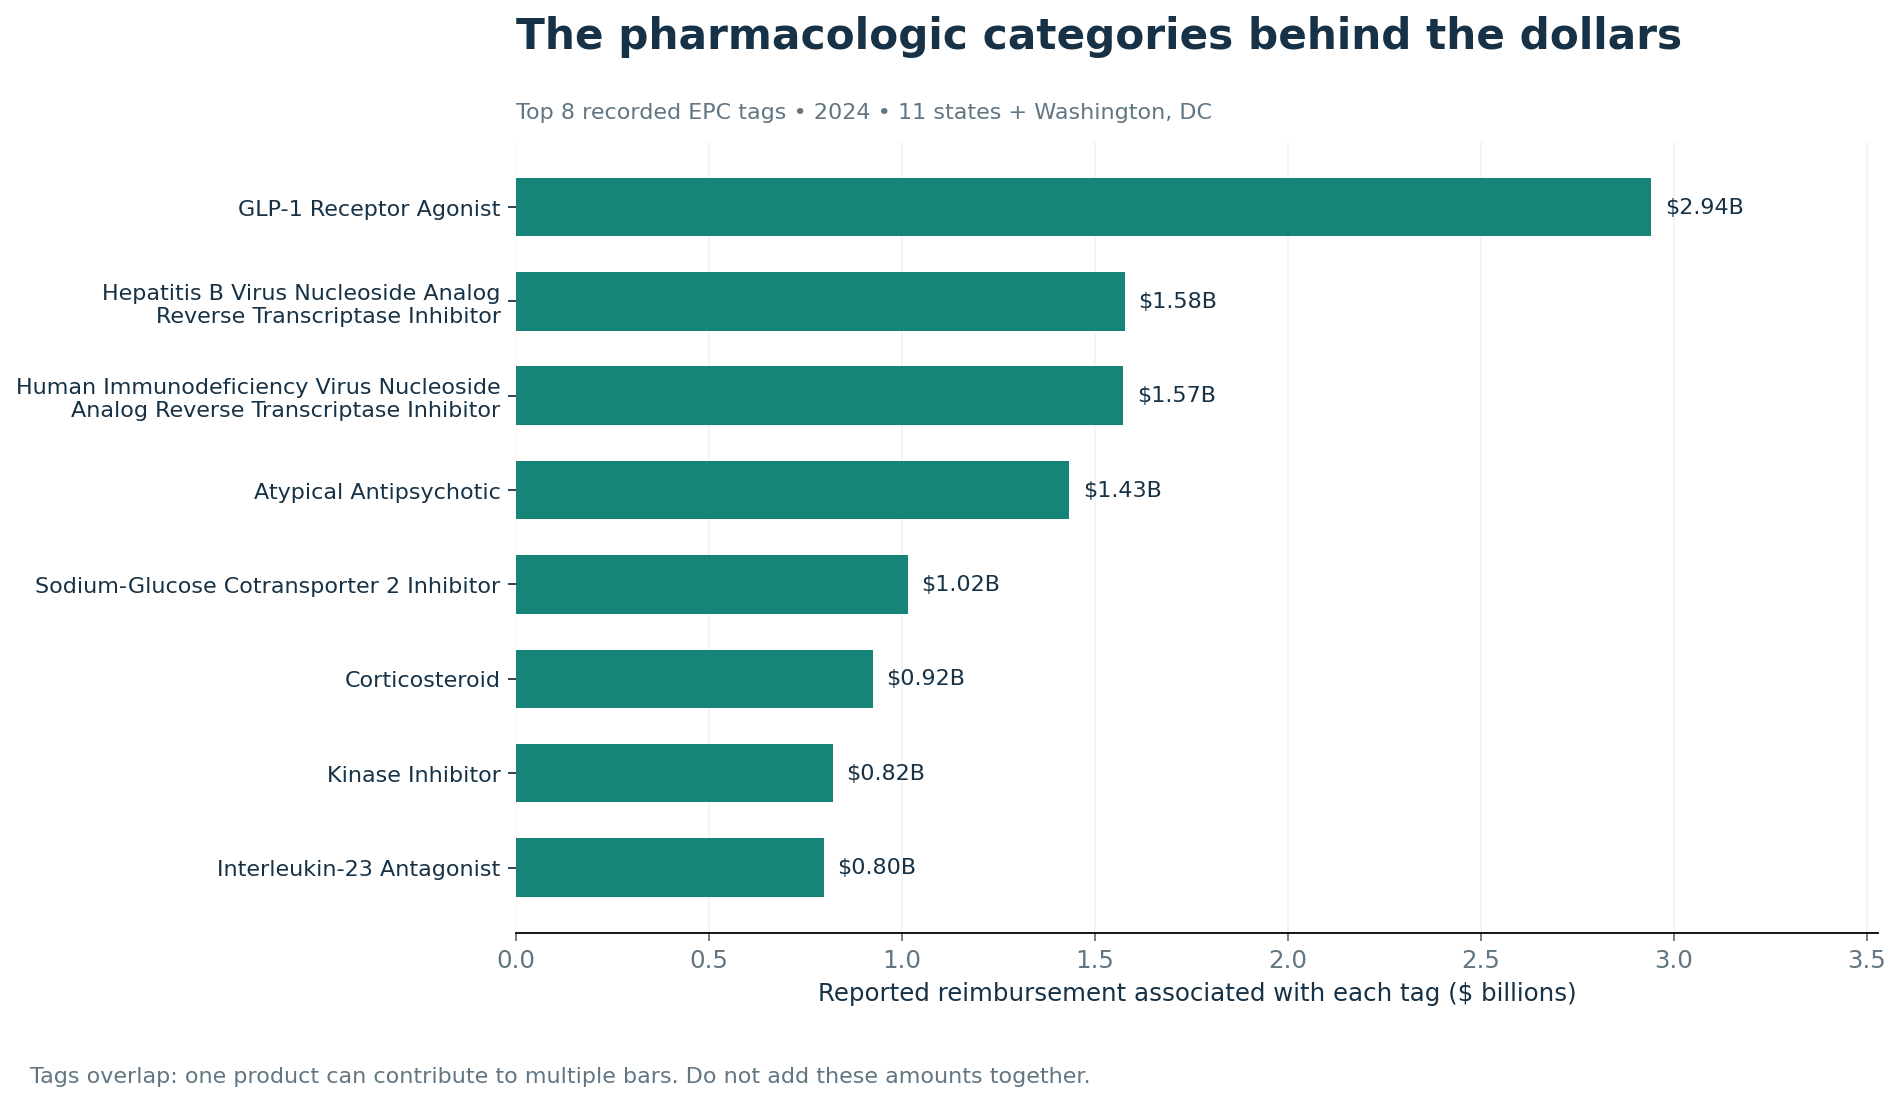

**What I learned:** products carrying the GLP-1 Receptor Agonist tag account for **$2.94B**. HIV-related reverse transcriptase inhibitors, atypical antipsychotics, and SGLT2 inhibitors also appear prominently. These categories help organize the product-level review.

I keep **$5.19B** without a recorded EPC tag or with unmatched metadata visible. I do not discard these dollars or infer a clinical class from an incomplete listing.

## Q3. Where do matched prices merit a savings review?

A large spending total does not tell me whether another product has a lower observed price. For that comparison, I require matching ingredient, dosage form, route, strength, and strength unit. I also match jurisdiction, quarter, and utilization type and check whether recorded marketing dates overlap the quarter.

Within each reporting group I compare NDA- and ANDA-listed prescription products. These application categories organize the comparison; they are not a complete brand/generic classification.

### Why I chose a unit-weighted price

I want to measure a gross reimbursement difference at observed utilization. I calculate **total reimbursement divided by total units** on each side, so a small and a large observation do not receive equal influence. A median instead describes the middle row-level price. The weighted calculation directly connects the price comparison to observed dollars.

For each matched group:

```text
Weighted reimbursement per unit = total reimbursement / total units
Signed gross gap = (NDA weighted price - ANDA weighted price) x NDA units
Positive gross gap = max(signed gross gap, 0)
```

As an arithmetic example, 100 NDA units at $10 per unit compared with a $2 ANDA price gives an $800 signed difference. This example illustrates the calculation; it is not a measured project observation or proof that 100 units can be substituted.


In [8]:
gaps, price_stats = reimbursement_gaps(joined)
print(f"Matched recorded formulations: {price_stats['distinct_paired_formulations']:,}")
print(f"Matched reporting groups: {price_stats['paired_strata']:,}")
print(f"Positive gross reimbursement gap: ${price_stats['illustrative_positive_gross_gap']:,.2f}")
print(f"Signed gross gap, including negative differences: ${price_stats['signed_gross_gap']:,.2f}")


Matched recorded formulations: 562
Matched reporting groups: 6,675
Positive gross reimbursement gap: $516,161,761.37
Signed gross gap, including negative differences: $506,733,293.57


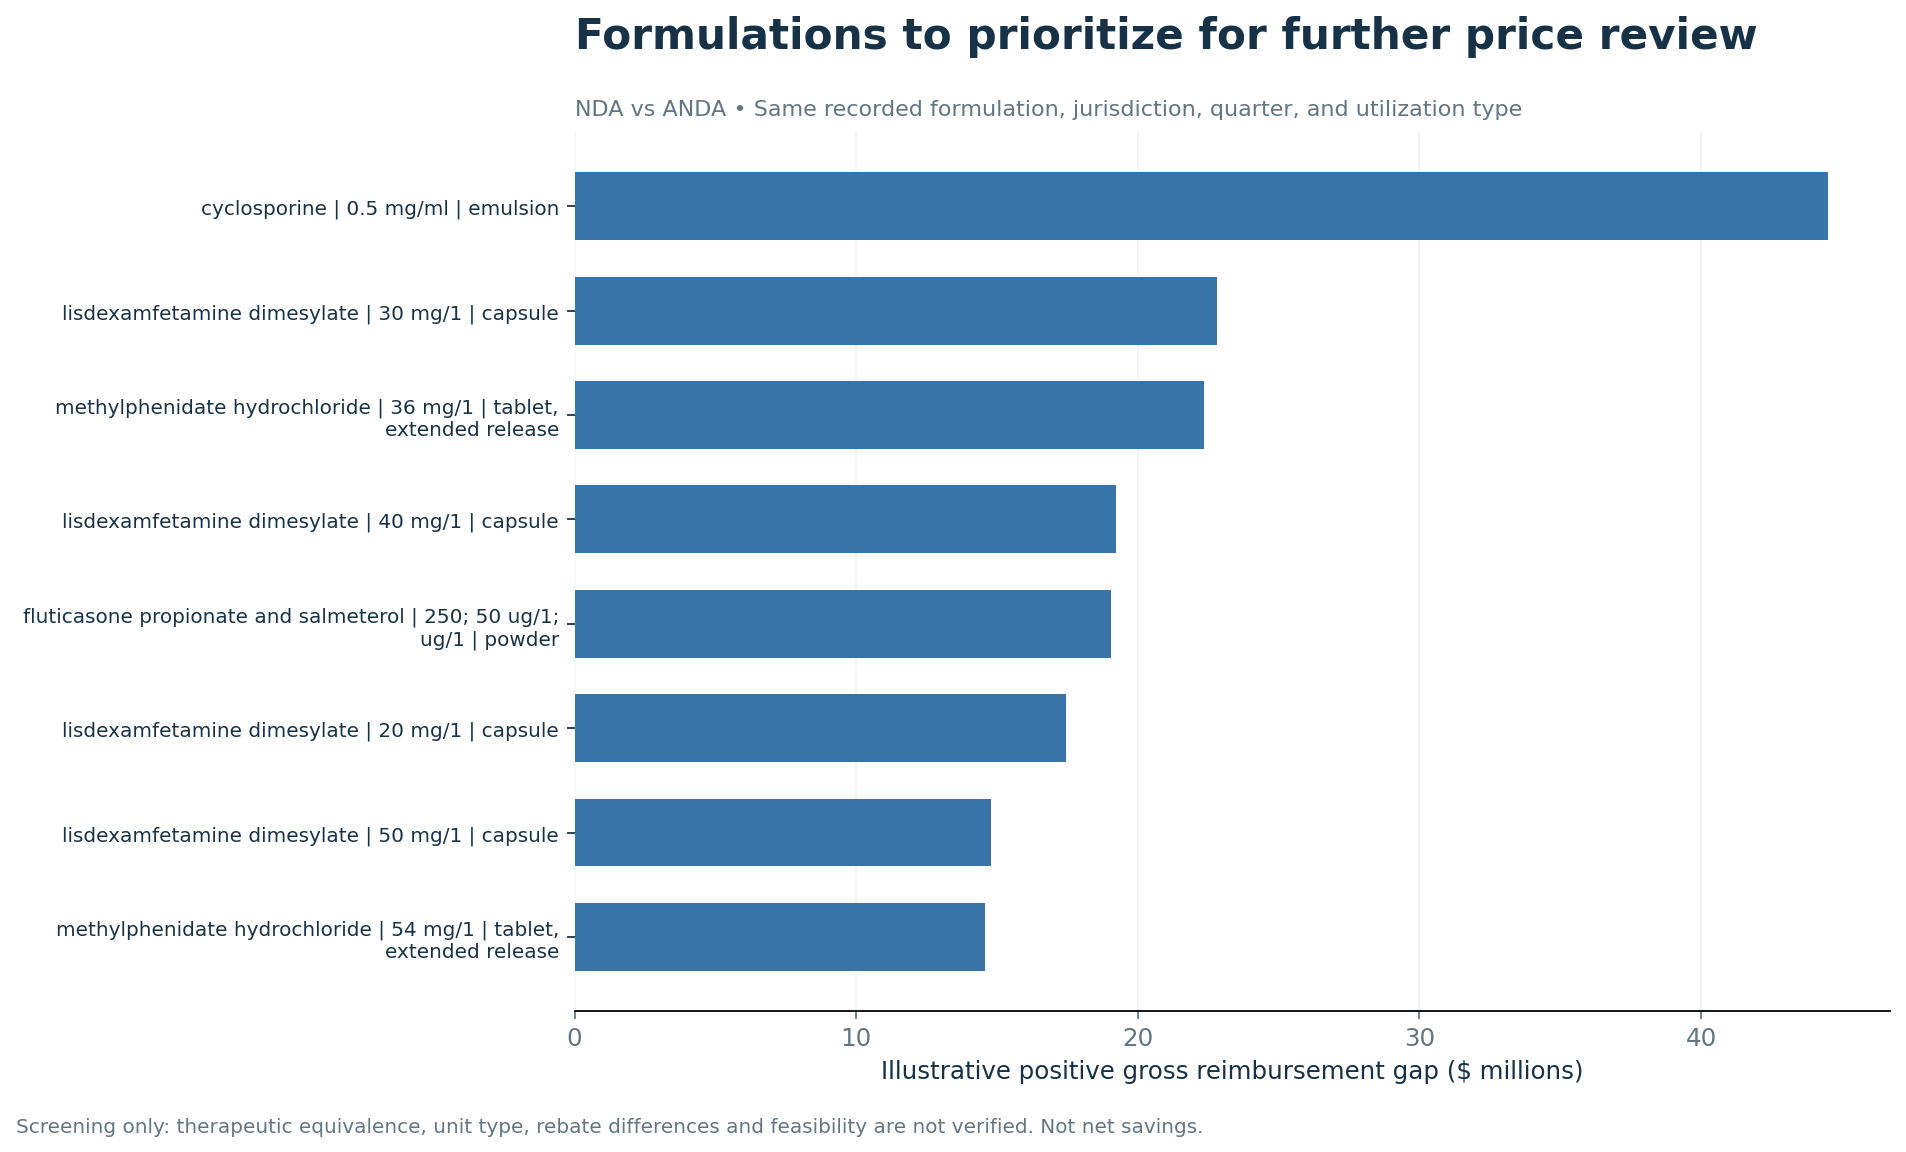

**What I learned:** the comparison identifies **562 formulations across 6,675 reporting groups**. Positive differences sum to **$516.16M**. Including negative differences gives a **$506.73M signed aggregate**.

I retain negative observations instead of assuming the ANDA side is always cheaper. I clip positive gaps within each reporting group before aggregating to formulation level; a formulation can consequently have a positive review gap even if its signed total is negative.

These amounts identify review candidates. Rebates, reimbursement unit types, therapeutic equivalence, and feasibility remain unverified, so I do not label the result achievable or net savings.

### How I interpret the scenario table

I mechanically scale the positive aggregate to show how the arithmetic changes with the fraction considered. The fractions are illustrative, not estimated adoption rates or clinically feasible substitution targets.


In [9]:
scenarios = pd.read_csv(ROOT / "reports/tables/illustrative_scenarios.csv")
scenario_view = scenarios[["hypothetical_fraction", "illustrative_gross_gap"]].copy()
scenario_view["hypothetical_fraction"] = scenario_view["hypothetical_fraction"].map(lambda x: f"{x:.0%}")
scenario_view["illustrative_gross_gap"] = scenario_view["illustrative_gross_gap"].map(lambda x: f"${x / 1e6:.2f}M")
print(scenario_view.to_string(index=False))


hypothetical_fraction illustrative_gross_gap
                  25%               $129.04M
                  50%               $258.08M
                  75%               $387.12M
                 100%               $516.16M


## Q4. Which products have potentially comparable alternatives?

I use the matched formulation list to examine which products appear on both sides of the comparison. A shared ingredient alone is insufficient: route, strength, dosage form, and release descriptors remain part of the match.

The following table keeps those descriptors visible alongside dollar exposure and the number of jurisdictions represented. It is a review list, not a clinical substitution list.


In [10]:
formulations = pd.read_csv(ROOT / "reports/tables/formulation_gap_ranking.csv", dtype={"strength": "string"})
candidates = formulations.head(5)[["ingredient", "dosage_form", "route", "strength", "strength_unit",
                                     "positive_gross_gap", "paired_strata", "jurisdictions"]].copy()
for row in candidates.itertuples(index=False):
    print(f"{row.ingredient} | {row.strength} {row.strength_unit}")
    print(f"  Form: {row.dosage_form}; route: {row.route}")
    print(f"  Positive gross gap: ${row.positive_gross_gap / 1e6:.2f}M")
    print(f"  Matched reporting groups: {row.paired_strata}; jurisdictions: {row.jurisdictions}")
    print()


cyclosporine | 0.5 mg/ml
  Form: emulsion; route: ophthalmic
  Positive gross gap: $44.50M
  Matched reporting groups: 10; jurisdictions: 3

lisdexamfetamine dimesylate | 30 mg/1
  Form: capsule; route: oral
  Positive gross gap: $22.83M
  Matched reporting groups: 38; jurisdictions: 10

methylphenidate hydrochloride | 36 mg/1
  Form: tablet, extended release; route: oral
  Positive gross gap: $22.34M
  Matched reporting groups: 41; jurisdictions: 10

lisdexamfetamine dimesylate | 40 mg/1
  Form: capsule; route: oral
  Positive gross gap: $19.21M
  Matched reporting groups: 37; jurisdictions: 9

fluticasone propionate and salmeterol | 250; 50 ug/1; ug/1
  Form: powder; route: respiratory (inhalation)
  Positive gross gap: $19.05M
  Matched reporting groups: 34; jurisdictions: 11



**What I learned:** cyclosporine ophthalmic emulsion at **0.5 mg/mL** has a **$44.50M** positive gross gap. Lisdexamfetamine dimesylate oral capsules at **30 mg** and methylphenidate hydrochloride oral extended-release tablets at **36 mg** have gaps of **$22.83M** and **$22.34M**.

The exact formulation is the analytical unit. I do not extend the cyclosporine observation to every product containing that ingredient.

Before acting, I would verify the reimbursement-unit basis, applicable therapeutic-equivalence evidence, product availability, patient suitability, and net rebate economics. The directory fields establish a recorded match; they do not establish all of those conditions.

## Q5. How do geography and reporting context affect the spending picture?

I return to the broader spending totals to understand their context. I compare jurisdictions alongside suppression rather than rank raw spending as an efficiency score. Enrollment, patient mix, drug mix, utilization, and reporting completeness can all influence the amounts.


In [11]:
coverage = pd.read_sql_query((ROOT / "sql/jurisdiction_coverage.sql").read_text(), connection)
view = coverage[["state", "source_records", "suppressed_record_share", "reimbursement"]].copy()
view["suppressed_record_share"] = view["suppressed_record_share"].map(lambda x: f"{x:.1%}")
view["reimbursement"] = view["reimbursement"].map(lambda x: f"${x / 1e9:.3f}B")
print(view.to_string(index=False))
ca_share = coverage.loc[coverage["state"].eq("CA"), "reimbursement"].sum() / coverage["reimbursement"].sum()
print(f"California share of reported reimbursement: {ca_share:.1%}")


state  source_records suppressed_record_share reimbursement
   CA          160323                   39.4%      $15.554B
   FL          124606                   49.7%       $3.164B
   CT           71030                   46.4%       $1.920B
   AZ           95905                   53.0%       $1.850B
   CO           95583                   54.2%       $1.454B
   GA          127780                   48.9%       $1.241B
   AL           68739                   47.2%       $1.000B
   AR           90130                   54.6%       $0.458B
   DC           74971                   72.5%       $0.247B
   DE           59686                   63.8%       $0.240B
   HI           36236                   57.7%       $0.205B
   AK           43586                   59.0%       $0.205B
California share of reported reimbursement: 56.5%


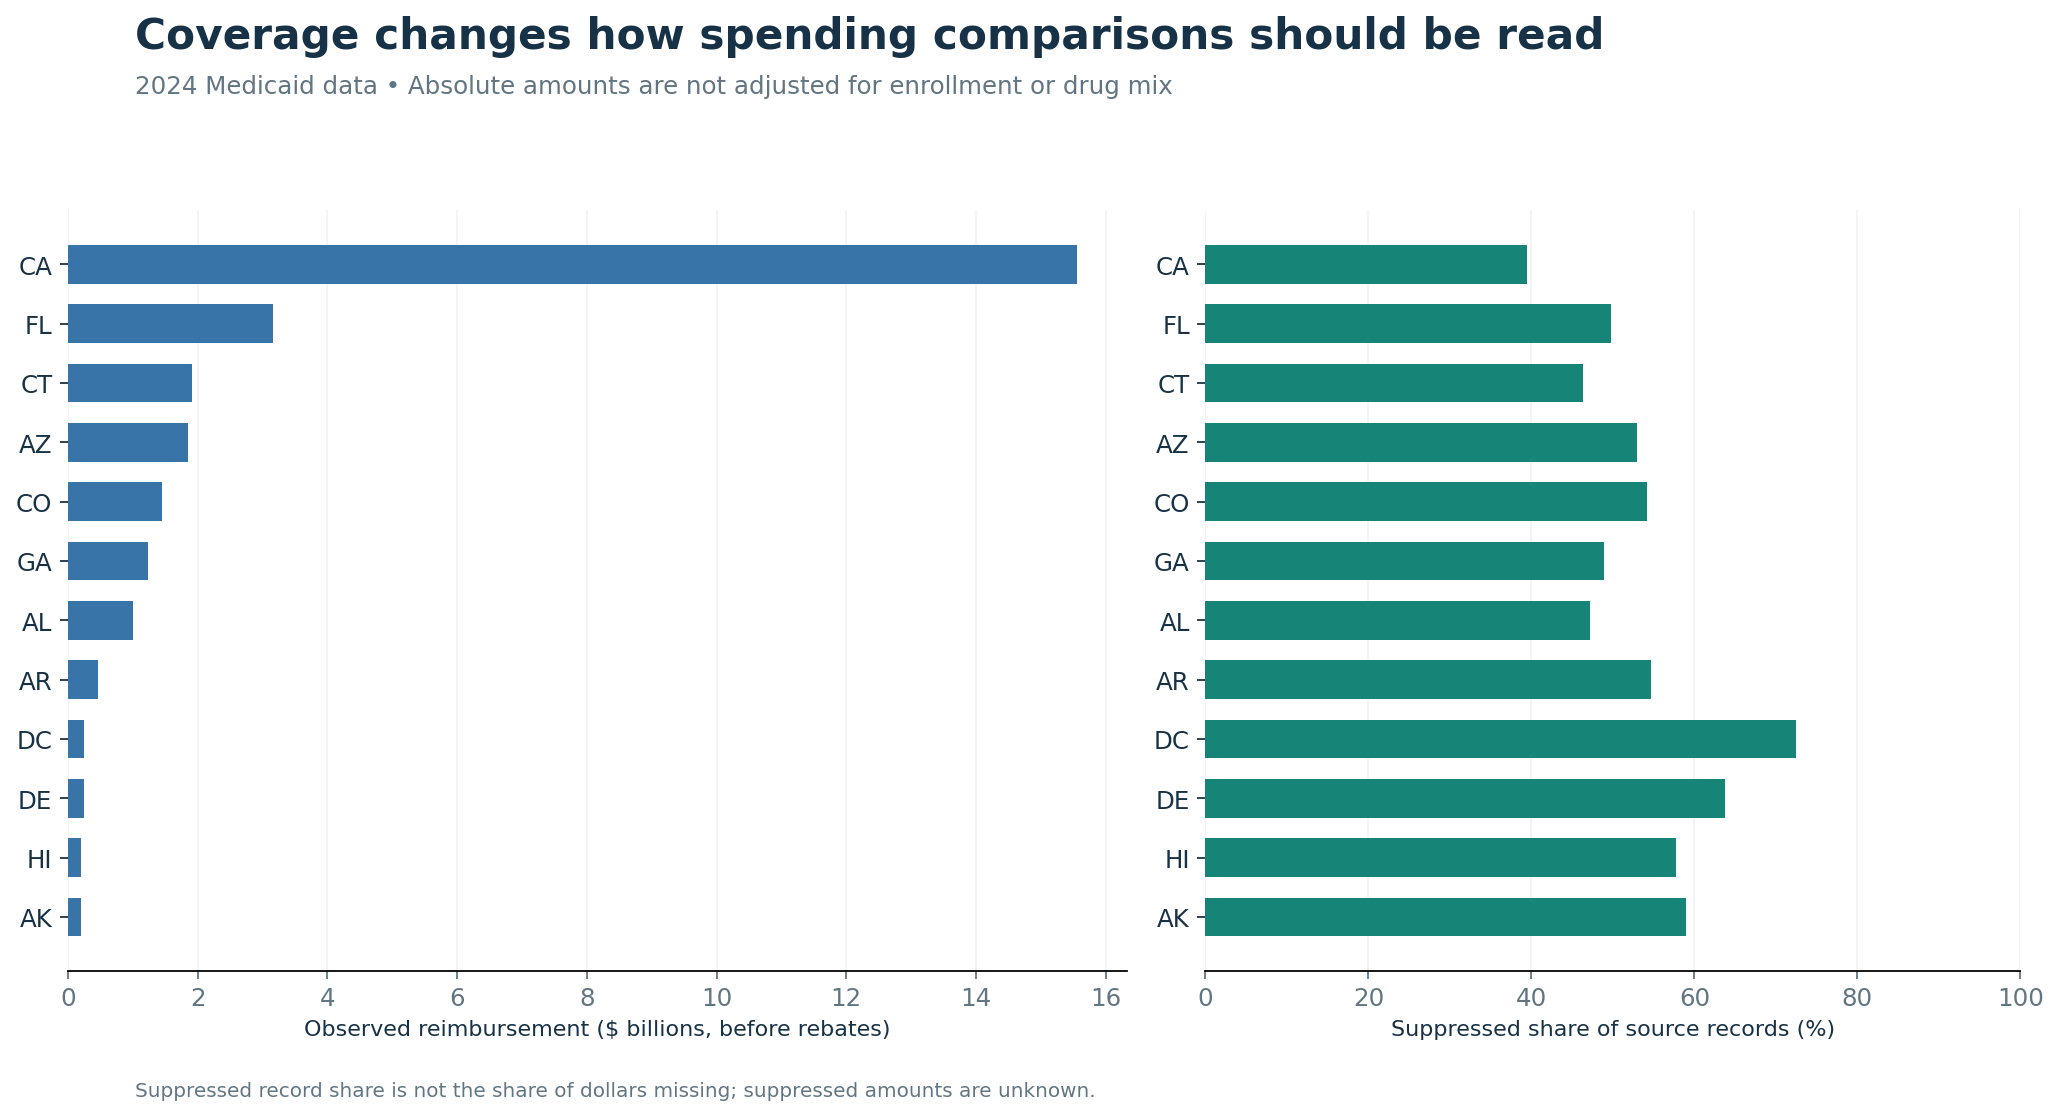

California contributes **56.5%** of this extract's reimbursement. That is an observed spending share, not evidence of higher prices or lower efficiency. A suppressed record percentage is also not the percentage of dollars missing.

I then compare reporting quarters using SQL `LAG`, and describe spending by the directory's recorded application categories.


In [12]:
quarters = pd.read_sql_query((ROOT / "sql/quarterly_spending.sql").read_text(), connection)
view = quarters[["quarter", "reimbursement", "reimbursement_per_prescription", "quarter_change"]].copy()
view["reimbursement"] = view["reimbursement"].map(lambda x: f"${x / 1e9:.3f}B")
view["reimbursement_per_prescription"] = view["reimbursement_per_prescription"].map(lambda x: f"${x:.2f}")
view["quarter_change"] = view["quarter_change"].map(lambda x: "--" if pd.isna(x) else f"{x:+.1%}")
print(view.to_string(index=False))


 quarter reimbursement reimbursement_per_prescription quarter_change
       1       $6.701B                        $145.91             --
       2       $6.365B                        $150.47          -5.0%
       3       $7.630B                        $163.21         +19.9%
       4       $6.845B                        $159.33         -10.3%


In [13]:
applications = pd.read_sql_query((ROOT / "sql/application_spending.sql").read_text(), connection)
view = applications.head(5)[["application_type", "reimbursement", "spend_share"]].copy()
view["reimbursement"] = view["reimbursement"].map(lambda x: f"${x / 1e9:.3f}B")
view["spend_share"] = view["spend_share"].map(lambda x: f"{x:.1%}")
print(view.to_string(index=False))


      application_type reimbursement spend_share
                   NDA      $15.998B       58.1%
                   BLA       $7.931B       28.8%
                  ANDA       $2.845B       10.3%
NDA AUTHORIZED GENERIC       $0.511B        1.9%
             Unmatched       $0.161B        0.6%


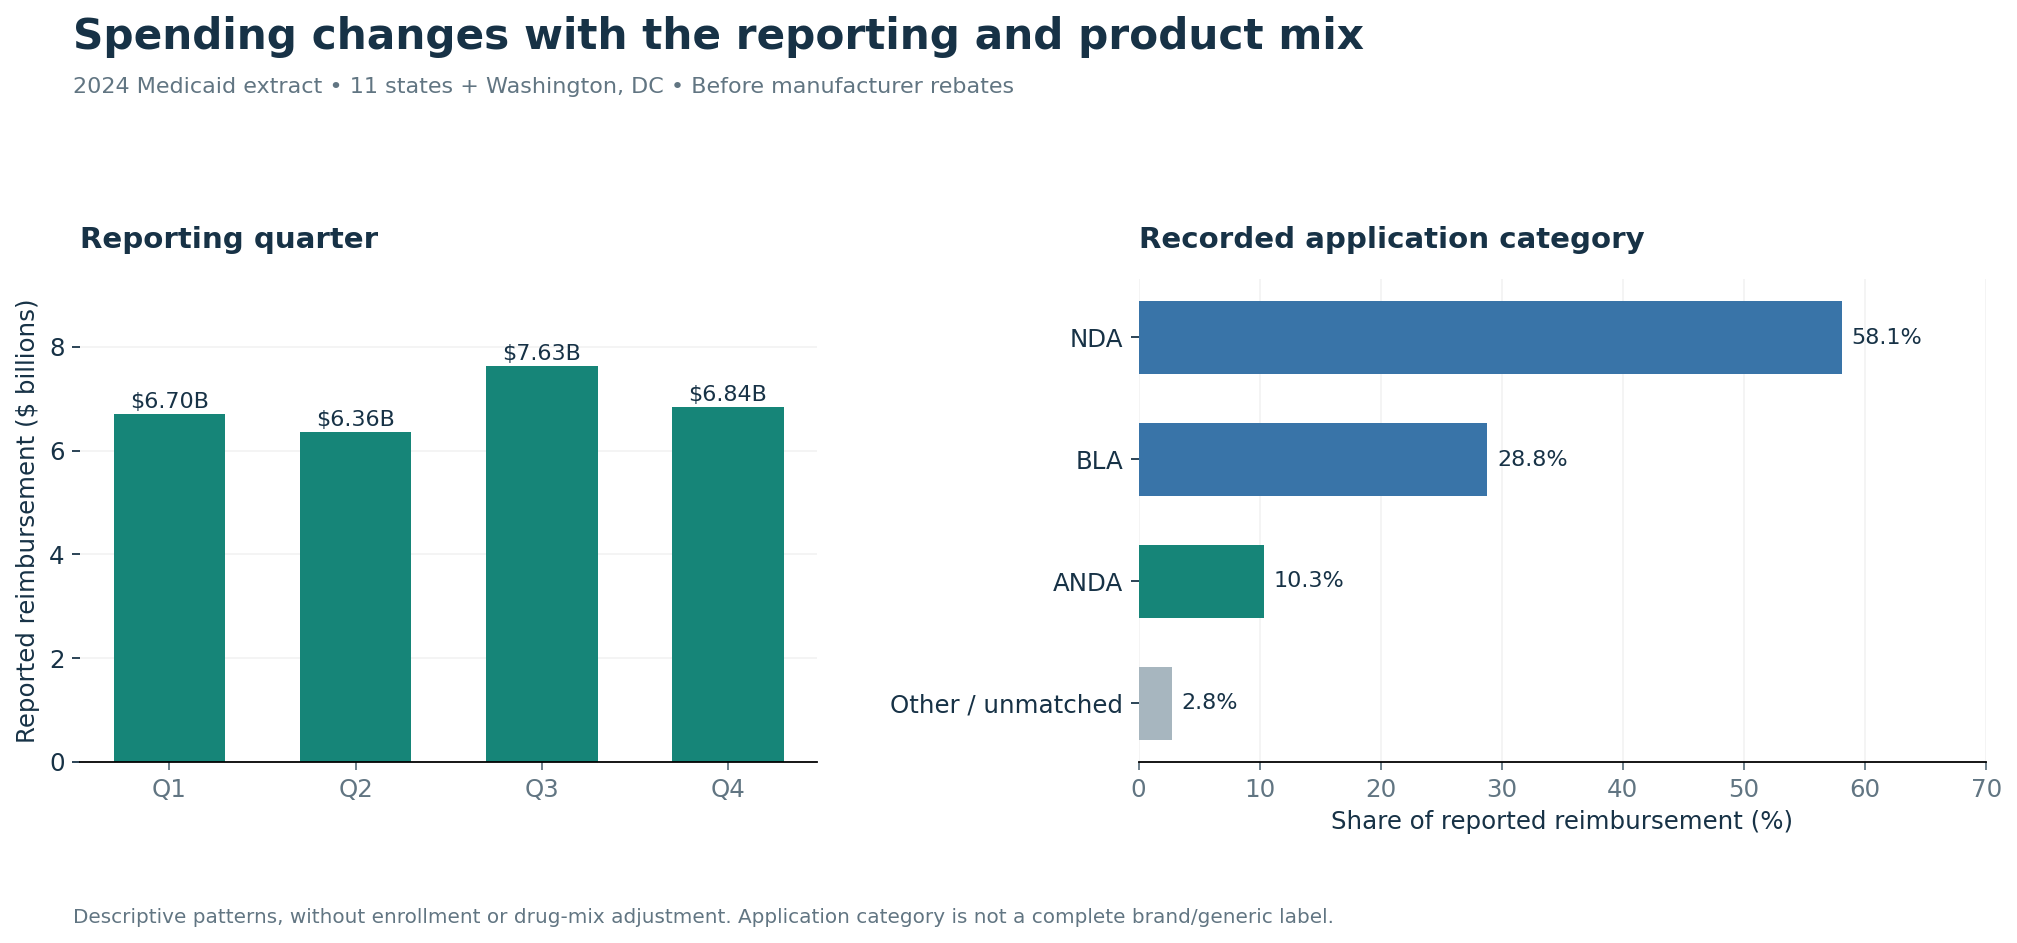

**What I learned:** Q3 has the highest reported reimbursement at **$7.63B**. NDA, BLA, and ANDA listings account for **58.1%**, **28.8%**, and **10.3%** of reported spending respectively.

These are descriptive patterns. The extract does not establish what caused a quarterly change, and application categories do not fully define brand/generic status. I use jurisdictions rather than broad regional claims because coverage includes only 11 states and DC.

## The decision I would take forward

I would start with the concentrated high-dollar product set, use pharmacologic tags to organize the review, then inspect the matched formulations with substantial gross differences. I would verify complete reporting, unit comparability, equivalence, availability, and net rebate effects before evaluating an intervention.

The analysis provides a reproducible starting point for that investigation. Its spending findings stand on observed totals; its price comparison supports a more specific review of potentially comparable products.

### Checking the results

I verify input checksums, reconciled spending totals, jurisdiction coverage, unique reporting-group matches, and price-comparison bounds. The same analytical checks run in GitHub Actions.

Details: [methodology](../docs/METHODOLOGY.md), [data guide](../data/README.md), [results guide](../reports/README.md), and [SQL queries](../sql/).


In [14]:
verify(ROOT)
connection.close()
del records, product_records, utilization, directory, joined


PASS: source checksums, spending totals, jurisdiction coverage, and price-comparison bounds
